# 4. Run coverage and selection of delayed jets

Unpaired bunch crossings provide a sample enriched in beam-induced background (BIB). Simulated jets matched to long-lived particle (LLP) decays provide the signal sample. This notebook identifies which runs contain cell measurements and quantifies how the momentum and calorimeter selections affect the number of delayed jets. [Model comparison](03_train_and_compare.ipynb)

In [ ]:
from collections import Counter
from pathlib import Path
import json

import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uproot
from IPython.display import display

project = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "DataForEmre").is_dir() and (folder / "notebooks").is_dir()
)
data = project / "DataForEmre"
outputs = project / "analysis/outputs"

## Cell data by run

Each run corresponds to a period of ATLAS data-taking. The cell and vertex files share run and event numbers, and a valid match also requires the same luminosity block. The vertex files store event numbers as signed integers. Interpreting their bits as unsigned integers allows comparison with the IDs in the cell files. The table counts events, each of which can contain several jets.

In [ ]:
unpaired = data / "non_collision/unpaired"
llp_files = sorted((data / "collision/LLP/N1N2_rpv_1400_10ns").glob("*.root"))
cell_files = sorted((unpaired / "physics_Background_NTuple_unsplit_v2").glob("*.root"))
vertex_files = sorted((unpaired / "user.ezaya.UNPAIRED_nPV_nocells.EXT0").glob("*.root"))
assert llp_files and cell_files and vertex_files, "Check the three local ROOT folders."

In [ ]:
cell_keys = set()
cell_runs = Counter()
cell_id = ["runNumber", "eventNumber", "lumiBlock"]
for path in cell_files:
    with uproot.open(path) as source:
        ids = source["JetContent"].arrays(cell_id, library="np")
    run, event, lumi = (ids[field] for field in cell_id)
    keys = set(zip(map(int, run), map(int, event), map(int, lumi)))
    assert len(keys) == len(run) and cell_keys.isdisjoint(keys), "Repeated cell event."
    cell_keys.update(keys)
    cell_runs.update(map(int, run))

In [ ]:
vertex_id = ["runNumber", "eventNumber", "lumiBlockNumber", "nPrimaryVertices"]
sidecar_runs = Counter()
vertices = {}

def add_vertex_chunk(chunk):
    run, event, lumi, count = (chunk[field] for field in vertex_id)
    runs, counts = np.unique(run, return_counts=True)
    sidecar_runs.update(dict(zip(map(int, runs), map(int, counts))))
    needed = np.isin(run, list(cell_runs))
    assert event.dtype == np.dtype("int32"), "Recheck event ID storage before matching."
    event = event.astype(np.uint32)
    for r, e, block, n in zip(run[needed], event[needed], lumi[needed], count[needed]):
        key = (int(r), int(e), int(block))
        if key in cell_keys:
            assert key not in vertices and int(n) >= 0, f"Repeated match or negative vertex count for {key}"
            vertices[key] = int(n)

In [ ]:
for path in vertex_files:
    with uproot.open(path) as source:
        for chunk in source["BIB"].iterate(vertex_id, step_size=100_000, library="np"):
            add_vertex_chunk(chunk)

runs = sorted(cell_runs.keys() | sidecar_runs.keys())
run_table = pd.DataFrame({
    "Run": runs,
    "Events with cells": [cell_runs[run] for run in runs],
    "Rows in vertex files": [sidecar_runs[run] for run in runs],
}).set_index("Run")
display(run_table)
assert cell_keys == vertices.keys(), "Some local cell events have no valid vertex match."

The local cell files cover unpaired run **484258**. Run **486706** has jet variables in the files without cells. An independent test of ParT on that run requires its cell measurements.

## Effect of the selection thresholds

The unpaired sample requires zero reconstructed primary vertices. The simulated signal sample requires a jet matched to an LLP decay. Both use $|\eta|<1.7$. The reference selection requires $p_T\geq30$ GeV and energy in both calorimeters ($0<f_{\rm Tile}<1$). The next selection lowers the threshold to 15 GeV. The final selection also includes jets with Tile energy fractions of 0 or 1.

For ATLAS jet time $t$, the fraction of delayed jets after each selection is

$$
f_{\rm delayed}=\frac{N(t>3\,\mathrm{ns})}{N(\mathrm{all\ times})}.
$$

At the 30 GeV threshold, $240/3463=6.93\%$ of the selected unpaired jets are delayed. The table also gives the count in the narrower window $3<t\leq10$ ns.

In [ ]:
jet_fields = ["jet_pt", "jet_eta", "jet_time_ATLAS", "jet_TileEnergyFrac"]
jet_selections = [(30, True), (15, True), (15, False)]
selection_names = ["30 GeV, mixed", "15 GeV, mixed", "15 GeV, Tile fraction 0 to 1"]
region_names = ["All times", "Time > 3 ns", "3 < time ≤ 10 ns"]

def valid(values):
    return np.isfinite(values) & (values != -999999)

def zero_vertex_events(rows):
    run, event, lumi = (ak.to_numpy(rows[field]) for field in cell_id)
    keys = zip(run, event, lumi)
    return ak.Array([vertices[key] == 0 for key in keys])

In [ ]:
def jet_masks(rows, sample):
    pt, eta, time, tile = (rows[field] for field in jet_fields)
    valid_jet = valid(pt) & valid(eta) & valid(time) & (abs(eta) < 1.7)
    if sample == "LLP":
        valid_jet = valid_jet & (rows["jet_is_llp_matched"] == 1)
    else:
        valid_jet = valid_jet & zero_vertex_events(rows)
    mixed = (tile > 0) & (tile < 1)
    inclusive = (tile >= 0) & (tile <= 1)
    for min_pt, require_mixed in jet_selections:
        calorimeters = mixed if require_mixed else inclusive
        keep = valid_jet & (pt >= 1000 * min_pt) & calorimeters
        delayed = keep & (time > 3)
        yield keep, delayed, delayed & (time <= 10)

In [ ]:
def count_sample(paths, sample):
    fields = jet_fields + (cell_id if sample == "unpaired" else ["jet_is_llp_matched"])
    counts = np.zeros((len(jet_selections), len(region_names)), dtype=np.int64)
    for path in paths:
        with uproot.open(path) as source:
            batches = source["JetContent"].iterate(fields, step_size=10_000, library="ak")
            for rows in batches:
                for i, selections in enumerate(jet_masks(rows, sample)):
                    counts[i] += [int(ak.sum(keep)) for keep in selections]
    return counts

In [ ]:
selection_counts = {}
for sample, paths in [("LLP", llp_files), ("unpaired", cell_files)]:
    counts = count_sample(paths, sample)
    table = pd.DataFrame(counts, index=selection_names, columns=region_names)
    table["Delayed (%)"] = (100 * table["Time > 3 ns"] / table["All times"]).round(2)
    assert (table["All times"] >= table["Time > 3 ns"]).all()
    assert (table["Time > 3 ns"] >= table["3 < time ≤ 10 ns"]).all()
    assert (np.diff(counts, axis=0) >= 0).all()
    print(sample)
    display(table)
    selection_counts[sample] = table

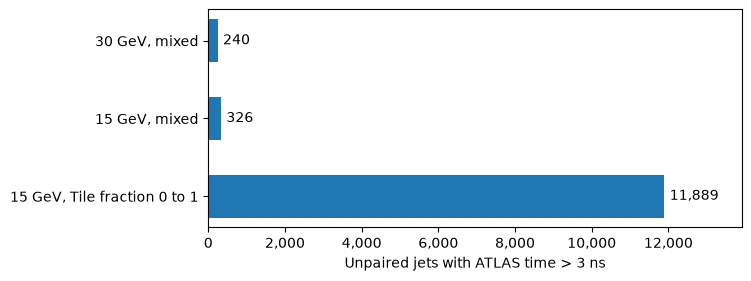

In [ ]:
delayed = selection_counts["unpaired"]["Time > 3 ns"]
fig, ax = plt.subplots(figsize=(7.4, 2.7), layout="constrained")
bars = ax.barh(delayed.index, delayed, color="tab:blue", height=0.55)
ax.bar_label(bars, labels=[f"{n:,}" for n in delayed], padding=4)
ax.invert_yaxis()
ax.set(xlabel="Unpaired jets with ATLAS time > 3 ns", xlim=(0, 1.17 * delayed.max()))
ax.xaxis.set_major_formatter("{x:,.0f}")
plt.show()

**Delayed unpaired jets by selection.** Bar lengths show counts before the train/test split. Lowering the momentum threshold from 30 to 15 GeV increases the count from **240 to 326** with energy required in both calorimeters (“mixed”). Including jets with all or none of their energy in Tile increases the count to **11,889**.

## Comparison across runs

These tables use earlier results from `analysis/outputs/`. The first compares models trained on jet-level variables across unpaired runs. Each model's threshold retained 95% of delayed LLP jets on validation. All runs share the same LLP test sample.

In [ ]:
def saved_file(study, name):
    path = outputs / study / name
    if path.is_file():
        return path
    print(f"Local report unavailable: {path.relative_to(project)}")
    return None

def ratio(success, total):
    return f"{int(success):,} / {int(total):,}"

In [ ]:
path = saved_file("unpaired_run_study", "results.csv")
if path is not None:
    report = pd.read_csv(path)
    delayed = report.query("region == 'delayed' and validation_region == 'delayed'").copy()
    delayed["Unpaired tagged / available"] = [ratio(hit, total) for hit, total in
        zip(delayed["unpaired_tagged"], delayed["unpaired_test_jets"])]
    labels = {"time_only": "Time only", "kinematics_only": "Kinematics only",
              "time_and_kinematics": "Time and kinematics"}
    display(delayed.pivot(index="run", columns="model", values="Unpaired tagged / available")
            .rename(columns=labels).reindex(columns=labels.values()))
    llp = delayed[["model", "llp_kept", "llp_test_jets"]].drop_duplicates().set_index("model")
    print("Delayed LLP test jets, shared across runs")
    display(llp.rename(index=labels, columns={"llp_kept": "LLP kept", "llp_test_jets": "LLP tested"}))

## Sensitivity to cell timing

Shuffling cell times within each jet tests whether ParT uses the association between a cell's time and its other features. For cell $i$ with time $t_i$ and position $\mathbf r_i$, a random permutation $\pi$ gives the mapping

$$
(t_i,\mathbf r_i)\longrightarrow(t_{\pi(i)},\mathbf r_i).
$$

The jet retains the same set of times, while their associations with position and energy change. The test uses the same trained ParT model and threshold before and after shuffling. A separate comparison uses only the negative cell count, $-N_{\rm cells}$, with its own validation threshold. [Cell timing fit](01_cells_and_selections.ipynb)

In [ ]:
path = saved_file("cell_input_study", "metrics.json")
if path is not None:
    report = json.loads(path.read_text())
    print("Median test cell counts", report["median_cell_count_test"])
    rows = []
    for method, stats in report["comparisons"]["delayed"].items():
        hits, totals = stats["confusion"], stats["class_counts"]
        rows.append({"Method": method.replace("_", " "),
                     "Unpaired tagged / total": ratio(hits["BIB_tagged_BIB"], totals["BIB"]),
                     "LLP kept / total": ratio(hits["LLP_kept_as_LLP"], totals["LLP"])})
    display(pd.DataFrame(rows).set_index("Method"))

Cell count alone tagged **41/42** delayed unpaired jets and retained **715/816** LLP jets. ParT retained **789/816** LLP jets before shuffling and fewer after each shuffle. The decrease suggests that ParT uses associations between cell times and other features. Separating the effects of position and energy would require a more specific test. Testing the result on a second unpaired run also requires cell data from that run.